In [1]:
from scripts.run_cbm import load_image, load_test_records

In [35]:
from IPython.display import display
import matplotlib.pyplot as plt
records = load_test_records()
for record in records:
    print(record["attribute_label"])
    # image = load_image(record)
    # plt.imshow(image.permute(1, 2, 0).numpy())   # (3,299,299) -> (299,299,3)
    # plt.show()
    break
    

[0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


In [ ]:
from rex_xai.lib import ReX
from rex_xai.responsibility.prediction import Prediction
from rex_xai.input.input_data import Data
import platform
from torchvision import transforms
import torch
from PIL import Image
from scripts.run_cbm import CBM, ConceptView

transform = transforms.Compose([
    transforms.CenterCrop(299),
    transforms.ToTensor(),                                   # (3, H, W), values in [0, 1]
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[2, 2, 2]),
])
model = ConceptView(cbm,)
# you have to include this
model_shape = ("N", 3, 299, 299)

if platform.uname().system == "Darwin":
    model.to("mps")
else:
    model.to("cpu")

# you have to write this
def preprocess(path, shape, device) -> Data:
    # open the image with mode "RGB"
    img = Image.open(path).convert("RGB")
    data = Data(img, shape, device, mode="RGB")
    # manually set the data to the transformed image for model consumption
    data.data = transform(img).unsqueeze(0).to(device)  # type: ignore
    # make a copy
    original = Image.open(path).convert("RGB")
    original = transforms.functional.center_crop(original, 299)
    data.input = original
    return data

def function_factory(concept:int):
    def prediction_function(mutants, target=None, raw=False):
        concepts = ConceptView                # list of 112 tensors, each (1, 1)
        probs = torch.sigmoid(concepts)
        probs = probs[:,concept]
        predictions = []
        for prob in probs:
            predictions.append(Prediction(pred=0 if prob.item() < 0.5 else 1,conf=prob.item()))
        return predictions
    return prediction_function

In [36]:
from scripts.concept_experiment import (active_concepts, 
                                        explain_concept,
                                        explain_all_active, 
                                        inactive_concepts,
                                        setup_rex)
from scripts.run_cbm import CBM
import torch 

device = "cuda" if torch.cuda.is_available() else "cpu"
cbm = CBM("concept", device=device)            # switch model by name
img = records[0]
# 1) quick test of a single concept; check rex_conf ~= p (preprocessing sanity check)
active, probs = active_concepts(cbm, img, device)
print(f"{len(active)} active concepts")
k = active[0]
# out = explain_concept(cbm, k, img, device,target_classification=0)
# print(f"concept {k}: p={probs[k]:.4f} vs ReX conf={out['target_confidence']:.4f}")
rex, image  = setup_rex(cbm, k, img, device)
print(active)
# 2) all active concepts for this image
# results = explain_all_active(cbm, img, device, iters=20, search_limit=1000)

d:\App\anaconda3\envs\rex\Lib\site-packages\torch\serialization.py:1832: SourceChangeWarning: source code of class 'torch.nn.modules.conv.Conv2d' has changed. you can retrieve the original source code by accessing the object's source attribute or set `torch.nn.Module.dump_patches = True` and use the patch tool to revert the changes.
  _check_container_source(*data)
d:\App\anaconda3\envs\rex\Lib\site-packages\torch\serialization.py:1832: SourceChangeWarning: source code of class 'torch.nn.modules.batchnorm.BatchNorm2d' has changed. you can retrieve the original source code by accessing the object's source attribute or set `torch.nn.Module.dump_patches = True` and use the patch tool to revert the changes.
  _check_container_source(*data)
d:\App\anaconda3\envs\rex\Lib\site-packages\torch\serialization.py:1832: SourceChangeWarning: source code of class 'torch.nn.modules.container.ModuleList' has changed. you can retrieve the original source code by accessing the object's source attribute o

8 active concepts
[1, 22, 50, 51, 79, 83, 86, 89]


In [52]:
import random
def sample_active_concepts(record):
    attribute = record["attribute_label"]
    active_concepts = []
    print(attribute)
    for concept, i in enumerate(attribute):
        if concept == 1:
            active_concepts.append(i)
    print(active_concepts)
    return random.sample(active_concepts,len(active_concepts)//3) if len(active_concepts)//3 > 0 else active_concepts


In [ ]:
print(sample_active_concepts(records[0]))
print(active)

[0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
[1]
[1]
[1, 22, 50, 51, 79, 83, 86, 89]


: 

In [ ]:
from rex_xai.lib import ReX
device = "cuda" if torch.cuda.is_available() else "cpu"
cbm = CBM("concept", device=device)
def run_frozen_experiment(cbm,k):
    full_rex = setup_rex(cbm, k, img, device,concept=False)
    full_rex_masks, full_rex_stats = run_rex_seeds(full_rex,[10,55,37])

    frozen_rex = 
    # run rex on original image
    # a new rex with frozen concepts
    # new rex masks

In [5]:
def run_rex_seeds(rex, seeds, threshold=0.0):
    masks = {}
    stats = {}
    rex.args.minimum_confidence_threshold = threshold

    for seed in seeds:
        rex.args.seed = seed
        rex.calculate_responsibility().generate_explanation_object()
        stats[seed] = dict(rex.stats)
        rex.extract_sufficient_explanation()

        mask = rex.explanation.sufficiency_mask
        assert (mask[0] == mask[1]).all() and (mask[0] == mask[2]).all()  # all 3 channels identical
        masks[seed] = mask[0].clone()                                      # keep one [299, 299] channel

    return masks, stats


In [32]:
masks, stats = run_rex_seeds(rex,[10,33,57])

Extracting global explanation:   1%|▏         | 119/8940 [00:42<52:41,  2.79it/s]  


In [28]:
def plot_img_and_seg(img, bird, save_path=None):
    fig, axes = plt.subplots(1, 3, figsize=(12, 4))

    #cropped image
    axes[0].imshow(img)

    # Masked Image
    bird_np = bird #.cpu().numpy()
    axes[1].imshow(bird_np, cmap="gray")

    # Cropped image with mask on top
    axes[2].imshow(img)
    axes[2].imshow(bird_np, alpha=0.4, cmap="Reds")

    titles = ["Image", f"Bird mask ({bird.float().mean().item():.0%} of image)", "Overlay"]
    for axis, title in zip(axes, titles):
        axis.set_title(title) 
        axis.axis("off")

    plt.tight_layout()

    if save_path is not None:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")

    plt.show()

def bird_share(explanation, bird):
    share = (explanation & bird).sum() / explanation.sum()
    size = explanation.float().mean().item()

    return size, share.item()

def plot_seed_overlays(img, bird, masks, save_path=None):
    seeds = list(masks.keys())
    fig, axes = plt.subplots(1, len(seeds), figsize=(4 * len(seeds), 4))
    axes = np.atleast_1d(axes)                        # works for 1 seed too
    bird_np = bird.cpu().numpy()                      # GPU tensor → numpy, as before

    for axis, seed in zip(axes, seeds):
        explanation = masks[seed].cpu().numpy()  
        
        on = explanation & bird_np    # explanation pixels that are bird
        off = explanation & ~bird_np  # explanation pixels that are not bird
        
        overlay = np.zeros((*explanation.shape, 4))   # RGBA layer
        overlay[on] = [0, 1, 0, 0.5]   # green
        overlay[off] = [1, 0, 0, 0.5]  # red

        # fraction of the image the explanation covers
        # fraction of the explanation on the bird
        size, share = bird_share(masks[seed], bird)
        
        axis.imshow(img)
        axis.imshow(overlay)
        axis.set_title(f"seed {seed}: {size:.1%} of image, {share:.0%} on bird")
        axis.axis("off")

    plt.tight_layout()
    if save_path is not None:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()

In [ ]:
from scripts.concept_experiment import (image_path,crop_image)
import numpy as np
from pathlib import Path
from PIL import Image
def get_bird_mask(record, resol=299):
    segmentation_path = Path(str(image_path(record)).replace("\\images\\", "\\segmentations\\")).with_suffix(".png")
    seg_img = Image.open(segmentation_path).convert("L")
    cropped_seg_img = crop_image(seg_img, resol)
    cropped_tensor = torch.from_numpy(np.array(cropped_seg_img))
    return (cropped_tensor > 127).to(device)

D:\XAI\CUB_200_2011\segmentations\001.Black_footed_Albatross\Black_Footed_Albatross_0078_796126.png


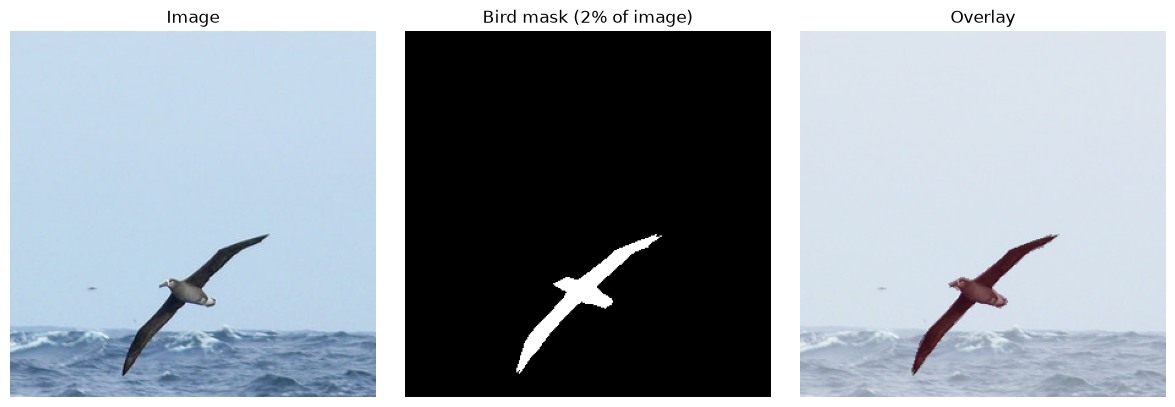

D:\XAI\CUB_200_2011\segmentations\001.Black_footed_Albatross\Black_Footed_Albatross_0078_796126.png


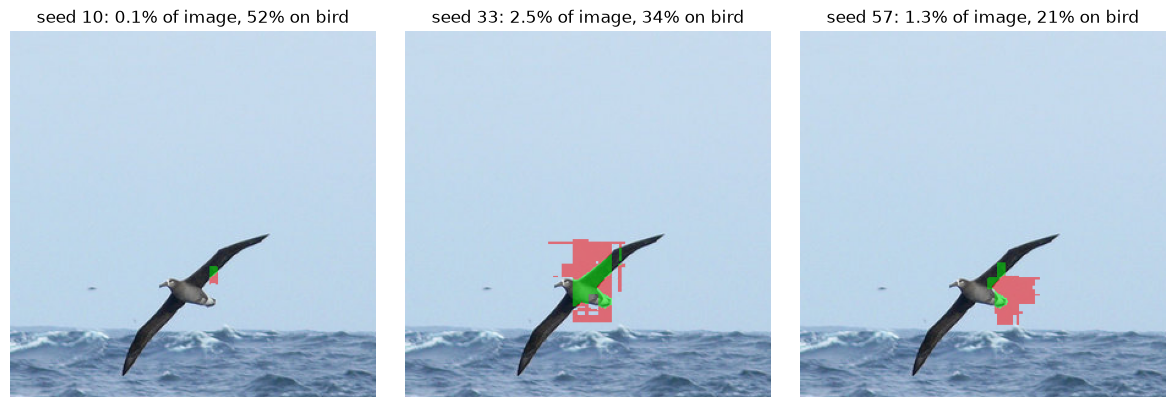

In [33]:
plot_img_and_seg(crop_image(image,299),get_bird_mask(img))
plot_seed_overlays(crop_image(image,299),get_bird_mask(img),masks)

In [30]:
stats

{10: {'total_passing': 785,
  'total_failing': 27,
  'max_depth_reached': 4,
  'avg_box_size': 1329.875},
 33: {'total_passing': 870,
  'total_failing': 12,
  'max_depth_reached': 4,
  'avg_box_size': 56.8875},
 57: {'total_passing': 801,
  'total_failing': 25,
  'max_depth_reached': 4,
  'avg_box_size': 244.25}}